# Implementing a Deep Averaging Network for Sentiment Analysis

## About This Project

In this project, you will use [PyTorch](https://pytorch.org/) (and [TensorFlow](https://www.tensorflow.org/)) to implement a Deep Averaging Network (DAN) for sentiment classification.

### Evaluation

**This project must be successfully completed and submitted in order to receive credit for this course. Your score on this project will be included in your final grade calculation.**
    
You are expected to write code where you see `# YOUR CODE HERE` within the cells of this notebook. Not all cells will be graded; code input cells followed by cells marked with `# Auto-graded test cell` will be graded. Upon submitting your work, the code you write at these designated positions will be assessed using an "auto-grader" that will run all test cells to assess your code. You will receive feedback from the auto-grader that will identify any errors in your code. Use this feedback to improve your code if you need to resubmit. Be sure not to change the names of any provided functions, classes, or variables within the existing code cells, as this will interfere with the auto-grader. Also, remember to execute all code cells sequentially, not just those you’ve edited, to ensure your code runs properly.
    
You can resubmit your work as many times as necessary before the submission deadline. If you experience difficulty or have questions about this exercise, use the Q&A discussion board to engage with your peers or seek assistance from the instructor.

Before starting your work, please review [eCornell's policy regarding plagiarism](https://s3.amazonaws.com/ecornell/global/eCornellPlagiarismPolicy.pdf) (the presentation of someone else's work as your own without source credit).

### Submit Code for Auto-Grader Feedback

Once you have completed your work on this notebook, you will submit your code for auto-grader review. Follow these steps:

1. **Save your notebook.**

2. **Mark as Completed** — In the blue menu bar along the top of this code exercise window, you’ll see a menu item called **Education**. In the **Education** menu, click **Mark as Completed** to submit your code for auto-grader/instructor review. This process will take a moment and a progress bar will show you the status of your submission.

3. **Review your results** — Once your work is marked as complete, the results of the auto-grader will automatically be presented in a new tab within the code exercise window. You can click on the assessment name in this feedback window to see more details regarding specific feedback/errors in your code submission.

4. **Repeat, if necessary** — The Jupyter Notebook will always remain accessible in the first tabbed window of the exercise. To reattempt the work, you will first need to click **Mark as Uncompleted** in the **Education** menu and then proceed to make edits to the notebook. Once you are ready to resubmit, follow steps one through three. You can repeat this procedure as many times as necessary.

You can also download a copy of this notebook in multiple formats using the **Save and Export Notebook As** option in the **File** menu above.

## Getting Started

### Python Initialization

Please run all the code cells in this section to properly initialize your Python kernel. You should be running a version of Python 3.x.

In [1]:
%load_ext autoreload

In [2]:
%autoreload 2

import math
import numpy as np

# Non-interactive matplotlib plots
%matplotlib inline
import matplotlib.pyplot as plt

# PyTorch and submodules
import torch
import torch.nn as nn
import torchvision
from torch.nn import functional as F
from torchvision import datasets, transforms

# TensorFlow (with messages suppressed)
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf

import sys
sys.path.append("/home/codio/workspace/.modules")
from helper import *

The next cell reports the version of Python, PyTorch+CUDA, and TensorFlow. It also determines whether PyTorch and TensorFlow are using the GPU or only the CPU. For computationally intensive models, training on the GPU can be significantly faster than training on the CPU alone. In this project, the GPU is about three times faster.

In [3]:
print("Python version:", sys.version.split(" ")[0])
print("PyTorch+CUDA version:", torch.__version__)
print("TensorFlow version:", tf.__version__)
print()

gpu_available_torch = torch.cuda.is_available()
if gpu_available_torch:
    print("PyTorch is using the GPU.")
    torch.cuda.manual_seed(1)  # Seed the random number generator
else:
    print("PyTorch is only using the CPU.")
    torch.manual_seed(1)  # Seed the random number generator

gpu_list = tf.config.list_physical_devices("GPU")
if len(gpu_list) > 0:
    print("TensorFlow is using the GPU.")
else:
    print("TensorFlow is only using the CPU.")

Python version: 3.12.5
PyTorch+CUDA version: 2.3.1+cu121
TensorFlow version: 2.16.2

PyTorch is using the GPU.
TensorFlow is using the GPU.


## PyTorch Approach

### Part One: Load Dataset [Ungraded]

We use the [multi-domain sentiment](https://www.cs.jhu.edu/~mdredze/datasets/sentiment/) dataset created by [Professor Mark Dredze](https://www.cs.jhu.edu/~mdredze/) for our project. This dataset contains product reviews taken from Amazon.com from many product types and the reviews are labeled positive and negative. In particular, we only consider the reviews for book for our project. To make things easier for you, we also created a dictionary where you will only consider the words in this dictionary when you are constructing the word embedding for your deep averaging network.

Run the following two cells to load the data and see a positive and a negative review. Please keep the following in mind:

- Calling `load_data()` returns the training review, test review, and vocabulary.

- The vocabulary variable `vocab` is a dictionary with key-value pairs (word, index), i.e., `vocab[word]` is `index`.

- We will use this vocabulary to construct bag-of-word (bow) features.

In [4]:
# Load data
review_train, review_test, vocab = load_data()

# Label 0: negative review
# Label 1: positive review
label_meaning = ["Negative", "Positive"]

print("Number of Training Reviews:", review_train.shape[0])
print("Number of Test Reviews:", review_test.shape[0])
print("Number of Words in the Vocabulary:", len(vocab))

Number of Training Reviews: 1787
Number of Test Reviews: 200
Number of Words in the Vocabulary: 4380


Run the next cell to print a positive and negative training review.

In [5]:
print("A Positive Training Review:", review_train.iloc[0]["review"])
print("A Negative Training Review:", review_train.iloc[-1]["review"])

A Positive Training Review: This was perhaps the best of Johannes Steinhoff's books, since it does not  deal with his own stellar yet tragic WW II and post war career. The  insights of the average person living in Germany are of great importance to  both social and military historians alike. Steinhoff offered this  collective testament as a warning to all of us regarding war and the rise  of a dictator. As Johannes said in an interview, &quot;It is always the  civilians who suffer the most, yet are remembered the least.&quot

A Negative Training Review: I got to page 26 and gave up.  Lockes writings lack focus and are void of humour.  I read as much as I could with patience until it became clear this book was simply someone rambling on about nothing.  Save your money for something worth reading



We also created a function `generate_featurizer` which takes in a vocabulary and return a bow featurizer based on the vocabulary. Using the returned featurizer, you can convert a sentence into a bag-of-words feature vector. See the following cell for example:

In [6]:
# Create a simple vocabulary
simple_vocab = {"learn": 0, "machine": 1, "learning": 2, "teach": 3}

# Create a simple sentence that will be converted into bag-of-words features
simple_sentence = " I learn machine learning to teach machine how to learn."

# Create a featurizer by passing in the vocabulary
simple_featurizer = generate_featurizer(simple_vocab)

# Transform the sentence to its bag-of-words features
simple_featurizer.transform([simple_sentence]).toarray()

array([[2, 2, 1, 1]])

You should get `array([[2, 2, 1, 1]])` as output from the previous cell. This means that the sentence has 2 occurences of `"learn"`, 2 occurences of `"machine"`, 1 occurence of `"learning"`, and 1 occurence of `"teach"`.

Now we will use `generate_featurizer` to generate a featurizer based on the vocabulary `vocab` we provided:

In [7]:
bow_featurizer = generate_featurizer(vocab)

Using the featurizer, we will convert the training reviews and test reviews into a bag-of-words representation and PyTorch Tensor:

In [8]:
X_train = torch.Tensor(
    bow_featurizer.transform(review_train["review"].values).toarray()
)
y_train = torch.LongTensor(review_train["label"].values.flatten())

X_test = torch.Tensor(bow_featurizer.transform(review_test["review"].values).toarray())
y_test = torch.LongTensor(review_test["label"].values.flatten())

The next cell generates PyTorch datasets and dataloaders.

In [9]:
# Generate PyTorch datasets
trainset = torch.utils.data.TensorDataset(X_train, y_train)
testset = torch.utils.data.TensorDataset(X_test, y_test)

# Generate PyTorch dataloaders
trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=128, shuffle=True, drop_last=True
)
testloader = torch.utils.data.DataLoader(
    testset, batch_size=128, shuffle=True, drop_last=False
)

### Part Two: Implement a Deep Averaging Network [Graded]

We have defined a PyTorch network class `DAN` for you. You need to implement the forward pass for your deep averaging network. To start, first implement **`average`** that averages the words in a review and then implement **`forward`** that passes the "averaged" review to a linear layer to produce the model's belief.

For `average`, recall that multiplying the matrix of the bag-of-words with the word embeddings will get you the embedded representations for the reviews. You then want to average over all the different words in a review to get an "average" embedding for each review. Note that here, we compute a weighted average. Let $\mathbf{E}\in{\mathbb{R}}^{d\times v}$ be the embedding matrix with embedding dimensionality $d$ and vocabulary size $v$. The $i$-th column of $\mathbf{E}$ is the embedding of word $i$ in the vocabulary. We denote it by $\mathbf{E}[:, i]$. Further, let $\mathbf{x}\in{\mathbb{R}}^{v}$ be a bag-of-words input vector. We compute the average embedding as follows:

$$
\mathbf{a}=\frac{1}{\sum_i \mathbf{x}[i]}\sum_{j}\mathbf{E}[:,j]\mathbf{x}[j]
$$

In the function `average`, you need to compute this average for each input vector (the input `x` is a matrix of shape `(n, v)` of inputs). 

For the function `forward`, pass the output of `average` through the linear layer stored in `self.fc`.

Once you have implemented each function, running the next cell creates a Deep Averaging Network (`DAN`) model class, where `embedding_size` is the size of the word embedding we are going to learn.

In [12]:
class DAN(nn.Module):
    def __init__(self, vocab_size, embedding_size=32):
        super().__init__()

        # Create a word embedding of dimension embedding_size.
        # The variable self.embeds is now the matrix E,
        # where each column corresponds to the embedding of a word.
        self.embeds = torch.nn.Parameter(torch.randn(vocab_size, embedding_size))
        self.embeds.requires_grad_(True)
        
        # Add a final linear layer that computes the
        # 2D output from the averaged word embedding
        self.fc = nn.Linear(embedding_size, 2)

    def average(self, x):
        """
        This function takes in multiple inputs, stored in one tensor x.
        Each input is a bag-of-words representation of reviews.
        For each review, it retrieves the word embedding of each word in the
        review and averages them (weighted by the corresponding entry in x).

        Input:
            x: nxv torch Tensor such that each row corresponds
               to bag-of-words representation of a review

        Output:
            emb: nxd torch Tensor for the averaged review
        """
        emb = None

        # YOUR CODE HERE
        emb = (x @ self.embeds) / x.sum(dim=1, keepdim=True)
        # END OF YOUR CODE

        return emb

    def forward(self, x):
        """
        This function takes in a bag-of-words representation of reviews.
        It calls the self.average to get the averaged review and pass
        it through the linear layer to produce the model's belief.

        Input:
            x: nxv torch Tensor, where each row corresponds
               to bag-of-words representation of reviews

        Output:
            out: nx2 torch Tensor that corresponds to model belief of the input.
                 For instance, output[i][0] is is the model belief that the i-th
                 review is negative and output[i][1] is the model belief that
                 the i-th review is positive.
        """
        review_averaged = self.average(x)
        out = None

        # YOUR CODE HERE
        out = self.fc(review_averaged)
        # END OF YOUR CODE
        
        return out

Run the next cell to check your implementation of `average` and `forward`.

In [13]:
def average_test1():
    """
    Check that your average function output has the correct shape 
    """
    n = 10                                   # Number of reviews
    vocab_size = 5                           # Size of vocabulary
    embedding_size = 32                      # Size of word embedding
    model = DAN(vocab_size, embedding_size)  # Create the DAN
    X = torch.rand(n, vocab_size)
    output_size = model.average(X).shape
    return output_size[0] == n and output_size[1] == embedding_size


def average_test2():
    """
    First check that your average function output has the correct values
    """
    n = 10                                   # Number of reviews
    vocab_size = 3                           # Size of vocabulary
    embedding_size = 5                       # Size of word embedding
    model = DAN(vocab_size, embedding_size)  # Create the DAN

    # Generate a simple input with four rows
    X = torch.FloatTensor(
        [
            [1, 0, 0],
            [0, 1, 0],
            [0, 0, 1],
            [1, 1, 1],
        ]
    )

    # Given that the input has four rows, we know that the
    # first three rows correspond to the first three words.
    # The last row should be the average of the three words,
    # so the difference between the last row and the average
    # of the first three rows should be small.

    # Get the averaged reviews
    averaged_reviews = model.average(X)

    # Get the last row
    last_row = averaged_reviews[3]

    # Compute the average of the first three rows
    avg_first_rows = torch.mean(averaged_reviews[:3], dim=0)

    # Calculate the squared difference
    diff = torch.sum((avg_first_rows - last_row) ** 2).item()
    
    return diff < 1e-5


def average_test3():
    """
    Second check that your average function output has the correct values
    """
    n = 10                                   # Number of reviews
    vocab_size = 3                           # Size of vocabulary
    embedding_size = 5                       # Size of word embedding
    model = DAN(vocab_size, embedding_size)  # Create the DAN

    # Generate a simple input
    X = torch.FloatTensor([[1, 1, 1], [2, 2, 2]])

    # Since the 2nd review is a multiple of the first,
    # the two averaged review should be the same.

    # Get the averaged reviews
    averaged_reviews = model.average(X)

    # Compute the sum of squared differences
    diff = torch.sum((averaged_reviews[0] - averaged_reviews[1]) ** 2).item()

    return diff < 1e-5


def forward_test1():
    """
    Check that your forward function output has the correct shape
    """
    n = 10                                   # Number of reviews
    vocab_size = 5                           # Size of vocabulary
    embedding_size = 32                      # Size of word embedding
    model = DAN(vocab_size, embedding_size)  # Create the DAN
    X = torch.rand(n, vocab_size)            # Generate data

    # Call your forward function and get output size
    output_size = model(X).shape

    return output_size[0] == n and output_size[1] == 2


def forward_test2():
    """
    Check that your forward function output has the correct values
    """
    n = 10                                   # Number of reviews
    vocab_size = 5                           # Size of vocabulary
    embedding_size = 32                      # Size of embedding
    model = DAN(vocab_size, embedding_size)  # Create the DAN
    X = torch.rand(n, vocab_size)            # Generate data

    # Get the output of your forward function (forward pass)
    logits = model(X)

    # Get the intermediate averaged reviews
    averaged_reviews = model.average(X)

    # Get model beliefs using your intermediate average reviews
    logits2 = model.fc(averaged_reviews)

    return torch.sum((logits - logits2) ** 2).item() < 1e-5


runtest(average_test1, "average_test1")
runtest(average_test2, "average_test2")
runtest(average_test3, "average_test3")
runtest(forward_test1, "forward_test1")
runtest(forward_test2, "forward_test2")

Running Test: average_test1 ... ✔ Passed!
Running Test: average_test2 ... ✔ Passed!
Running Test: average_test3 ... ✔ Passed!
Running Test: forward_test1 ... ✔ Passed!
Running Test: forward_test2 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (average_test1)

In [ ]:
# Auto-graded test cell worth one point (average_test2)

In [ ]:
# Auto-graded test cell worth one point (average_test3

In [ ]:
# Auto-graded test cell worth one point (forward_test1)

In [ ]:
# Auto-graded test cell worth one point (forward_test2)

Run the next cell to create a Deep Averaging Network model and use the GPU is one is available.

In [14]:
model = DAN(len(vocab), embedding_size=32)
if gpu_available_torch:
    model = model.cuda()

### Part Three: Define the Loss Function and Optimizer [Ungraded]

Run the next cell to create your loss function and optimizer.

In [15]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=5)

### Part Four: Train the Network [Ungraded]

Run the following cell to train your network.

In [16]:
# Number of epochs
num_epochs = 400

# Start training
model.train()
for epoch in range(num_epochs):

    # Define variables to track running losses and accuracies
    running_loss = 0.0
    running_acc = 0.0
    count = 0

    for i, (X, y) in enumerate(trainloader):

        # Use GPU if available
        if gpu_available_torch:
            X = X.cuda()
            y = y.cuda()

        # Clear the gradient buffer
        optimizer.zero_grad()

        # Do forward propagation to get the model beliefs
        logits = model(X)

        # Compute the loss
        loss = loss_fn(logits, y)

        # Run a backward propagation to get the gradient
        loss.backward()

        # Update the model parameters
        optimizer.step()

        # Get the predictions
        pred = torch.argmax(logits, dim=1)

        # Update the running statistics
        running_acc += torch.sum((pred == y).float()).item()
        running_loss += loss.item()
        count += X.size(0)

    # Print running statistics after training for 100 epochs
    if (epoch + 1) % 100 == 0:
        acc = running_acc / count
        loss = running_loss / len(trainloader)
        print(f"Epoch: {epoch+1}/{num_epochs}, Accuracy: {acc:.4f}, Loss: {loss:.4f}")

Epoch: 100/400, Accuracy: 0.8365, Loss: 0.4112
Epoch: 200/400, Accuracy: 0.9976, Loss: 0.0219
Epoch: 300/400, Accuracy: 1.0000, Loss: 0.0059
Epoch: 400/400, Accuracy: 1.0000, Loss: 0.0033


### Part Five: Evaluate Your Model on the Test Data [Ungraded]

In [17]:
# Evaluate the model
model.eval()

# Define variables to keep track of the running accuracy
running_acc = 0.0
count = 0.0

for X, y in testloader:
    # Use gpu if available
    if gpu_available_torch:
        X = X.cuda()
        y = y.cuda()

    # Do a forward pass and tell PyTorch that no gradient is necessary to save memory
    with torch.no_grad():
        logits = model(X)

    # Calculate the prediction
    pred = torch.argmax(logits, dim=1)

    # Update the running stats
    running_acc += torch.sum((pred == y).float()).item()
    count += X.size(0)

print(f"PyTorch Test Accuracy: {100 * (running_acc / count):.2f}%")

PyTorch Test Accuracy: 87.50%


Run the following cells to see the a random test review and the model prediction. (You may observe that neural networks achieve high accuracy &mdash; but tend to be over-confident. This is because they achieve 100% training accuracy early on in the learning procedure and therefore learn that they tend to be always right.)

In [18]:
target = torch.randint(high=len(testset), size=(1,)).item()

review_target, label_target = review_test.iloc[target]
if gpu_available_torch:
    bog_target = testset[target][0].unsqueeze(0).cuda()
else:
    bog_target = testset[target][0].unsqueeze(0)


model.eval()
with torch.no_grad():
    logits_target = model(bog_target)

pred = torch.argmax(logits_target, dim=1)
probability = torch.exp(logits_target.squeeze()) / torch.sum(
    torch.exp(logits_target.squeeze())
)

print("Review:", review_target)
print("Ground Truth:", label_meaning[int(label_target)])
cer = 100.0 * probability[pred.item()]
print(f"Prediction: {label_meaning[pred.item()]} ({cer:.2f}% certainty)")

Review: Very topical. Easy read. Hope people in the know read this and give serious thought to the potential for something like this happening.  Gives good reason why border control should be taken more serious by everybody. Looking forward to reading other books by Mr. Bell

Ground Truth: Positive
Prediction: Negative (81.77% certainty)


## TensorFlow Approach

Run the next cell to convert the reviews to bow representation as a TensorFlow tensor.

In [19]:
X_train = tf.convert_to_tensor(
    bow_featurizer.transform(review_train["review"].values).toarray()
)
y_train = tf.convert_to_tensor(review_train["label"].values.flatten(), dtype=tf.int64)

X_test = tf.convert_to_tensor(
    bow_featurizer.transform(review_test["review"].values).toarray()
)
y_test = tf.convert_to_tensor(review_test["label"].values.flatten(), dtype=tf.int64)

Like we did in the previous projects, we will use the built-in functions `compile` and `fit` for our deep averaging network. But performing the averaging step is tricky in TensorFlow as it does not give us control over how forward propagation is performed. The solution to this problem is to define our own averaging layer in TensorFlow, which can be included in `Sequential` when creating the model.

In [20]:
class TFAveragingLayer(tf.keras.layers.Layer):
    def __init__(self, vocab_size, embedding_size=32):
        super().__init__()
        self.embeds = self.add_weight(shape=(vocab_size, embedding_size))

    def call(self, x):
        return tf.matmul(x, self.embeds) / tf.reduce_sum(x, axis=1, keepdims=True)


model_tf = tf.keras.Sequential(
    [
        tf.keras.Input(shape=(len(vocab),)),
        TFAveragingLayer(len(vocab), embedding_size=32),
        tf.keras.layers.Dense(2, activation=None),
    ]
)

model_tf.summary()

# Create optimizer and loss function
loss_fn_tf = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
optimizer_tf = tf.keras.optimizers.SGD(learning_rate=5.0)

model_tf.compile(optimizer=optimizer_tf, loss=loss_fn_tf, metrics=["accuracy"])
num_epochs = 100
history = model_tf.fit(
    X_train,
    y_train,
    epochs=num_epochs,
    verbose=0,
    callbacks=[ProgBarLoggerNEpochs(num_epochs, every_n=25)],
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ tf_averaging_layer              │ (None, 32)             │       140,160 │
│ (TFAveragingLayer)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 140,226 (547.76 KB)

 Trainable params: 140,226 (547.76 KB)

 Non-trainable params: 0 (0.00 B)

I0000 00:00:1787634366.153233     976 service.cc:145] XLA service 0x7adb94004340 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1787634366.153275     976 service.cc:153]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1787634366.603007     976 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Epoch: 25/100, Accuracy: 0.8802, Loss: 0.2756
Epoch: 50/100, Accuracy: 0.9933, Loss: 0.0359
Epoch: 75/100, Accuracy: 0.9994, Loss: 0.0092
Epoch: 100/100, Accuracy: 1.0000, Loss: 0.0034


**NOTE:** You can ignore `WARNING: All log messages before...` when running the previous cell.

The model will likely train quickly, reaching 100% accuracy after about 75 epochs. You can check by plotting the training losses in the next cell.

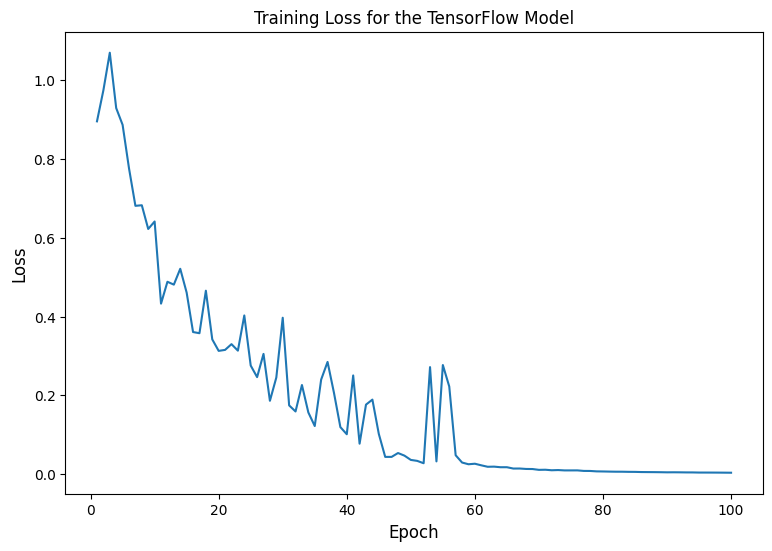

In [21]:
plt.figure(figsize=(9, 6))
plt.plot(np.arange(num_epochs) + 1, history.history["loss"])
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.title("Training Loss for the TensorFlow Model")
plt.show()

The next cell checks the test accuracy of the TensorFlow model.

In [22]:
## Evaluate the network
logits_tf = model_tf(X_test)

# Calculate the prediction
pred_tf = tf.argmax(logits_tf, axis=1)

# Update the running stats
acc = tf.reduce_mean(tf.cast(pred_tf == y_test, tf.float64)).numpy()
print(f"TensorFlow Test Accuracy: {100 * acc:.2f}%")

TensorFlow Test Accuracy: 91.50%


You can again check how confident this TensorFlow model is on the target test review. Like before, this model will be extremely confident in its prediction, regardless of correctness.

In [23]:
bog_target = tf.expand_dims(X_test[target], axis=0)
logits_target = model_tf(bog_target)

pred_tf2 = tf.argmax(logits_target, axis=1)
prob_num = tf.exp(tf.squeeze(logits_target))
prob_den = tf.reduce_sum(tf.exp(tf.squeeze(logits_target)))
probability = prob_num / prob_den

print("Review:", review_target)

real = label_meaning[int(label_target)]
pred = label_meaning[int(pred_tf2)]
cert = 100.0 * probability[int(pred_tf2)]
print("Ground Truth:", real)
print(f"Prediction: {pred} ({cert:.2f}% certainty)")

Review: Very topical. Easy read. Hope people in the know read this and give serious thought to the potential for something like this happening.  Gives good reason why border control should be taken more serious by everybody. Looking forward to reading other books by Mr. Bell

Ground Truth: Positive
Prediction: Negative (99.63% certainty)
